# 06. Anatomie des sous-estimations fortes et communes

> **English Overview (Step 6 — Anatomy of Common Underestimation Episodes):** An ex post description of the 44 dates (13 episodes) of simultaneous large underestimation. In each episode one future session dominates the five-day sum of squared returns (median share 60.7%), and the return at the first date of the episode is not extreme (`0/13` above its 95th percentile). The notebook describes realized episodes; it does not identify a cause or a warning signal.

**Question :** pourquoi les cinq prévisions du benchmark sous-estiment-elles fortement `RV5` aux mêmes dates, et que permettent réellement d'établir les seules données déjà utilisées ?

Ce notebook est exclusivement diagnostique. Il reproduit les modèles et critères du notebook 05 sans ajouter de donnée, modèle, réglage ou test statistique. La période 2016–2019 est déjà connue et reste exploratoire.

## 1. Séparation des informations

- **Disponible à la clôture de `t` :** rendement courant et passé, `HV5`, `HV20`, `HV60`, EWMA et prévisions des modèles.
- **Connu seulement après `t` :** `RV5`, erreurs, appartenance à un épisode, rendements `t+1…t+5`, séance future dominante.

Les informations futures servent uniquement à décrire l'issue observée. Elles ne sont jamais présentées comme un signal prédictif disponible en temps réel.

In [1]:
from datetime import datetime, timezone
from hashlib import sha256
from io import BytesIO, StringIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SOURCE_URL = (
    'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
    'F-F_Research_Data_Factors_daily_CSV.zip'
)
EXPECTED_SHA256 = '2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db'
SNAPSHOT_FILENAME = (
    'F-F_Research_Data_Factors_daily_202608_'
    f'sha256-{EXPECTED_SHA256}.zip'
)
HORIZON = 5
ANNUALIZATION_DAYS = 252
FEATURES = ['hv_5', 'hv_20', 'hv_60']
MODEL_NAMES = ['Constante', 'HV20', 'EWMA', 'Ridge', 'Gradient Boosting']
EXTENDED_MODEL_NAMES = ['Constante', 'HV20', 'EWMA', 'Ridge étendue', 'Boosting étendu']
RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')
print(f'pandas={pd.__version__}; numpy={np.__version__}; scikit-learn={sklearn.__version__}')

pandas=2.2.3; numpy=2.2.1; scikit-learn=1.6.1


## 2. Reconstitution des données et conventions validées

In [2]:
loaded_at_utc = datetime.now(timezone.utc).isoformat()
snapshot_candidates = [
    Path('data/raw/fama_french') / SNAPSHOT_FILENAME,
    Path('../data/raw/fama_french') / SNAPSHOT_FILENAME,
]
local_snapshot = next((path for path in snapshot_candidates if path.is_file()), None)
if local_snapshot is not None:
    archive_bytes = local_snapshot.read_bytes()
    data_origin = f'copie locale immuable : {local_snapshot.as_posix()}'
else:
    with urlopen(SOURCE_URL, timeout=60) as response:
        archive_bytes = response.read()
    data_origin = 'téléchargement en mémoire depuis la source officielle'

archive_sha256 = sha256(archive_bytes).hexdigest()
assert archive_sha256 == EXPECTED_SHA256
with ZipFile(BytesIO(archive_bytes)) as archive:
    members = archive.namelist()
    assert len(members) == 1
    text = archive.read(members[0]).decode('utf-8-sig')

lines = text.splitlines()
header_index = next(i for i, line in enumerate(lines) if line.strip().startswith(',Mkt-RF'))
data_lines = [lines[header_index]]
for line in lines[header_index + 1:]:
    first_field = line.split(',', 1)[0].strip()
    if len(first_field) == 8 and first_field.isdigit():
        data_lines.append(line)
    else:
        break

factors = pd.read_csv(StringIO('\n'.join(data_lines)))
factors = factors.rename(columns={factors.columns[0]: 'date'})
factors['date'] = pd.to_datetime(factors['date'].astype(str), format='%Y%m%d', errors='raise')
factors = factors.set_index('date')
assert factors.index.is_monotonic_increasing and not factors.index.has_duplicates
market_return = (factors['Mkt-RF'] + factors['RF']) / 100.0

print(f'Millésime : {lines[0]}')
print(f'Origine : {data_origin}')
print(f'Chargé à : {loaded_at_utc}')
print(f'SHA-256 : {archive_sha256}')
print(f'Observations : {len(factors):,}')

Millésime : This file was created by using the 202608 CRSP database.
Origine : copie locale immuable : data/raw/fama_french/F-F_Research_Data_Factors_daily_202608_sha256-2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db.zip
Chargé à : 2026-10-18T19:32:40.032932+00:00
SHA-256 : 2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db
Observations : 26,317


In [3]:
future_returns = pd.concat(
    {f'r_t_plus_{k}': market_return.shift(-k) for k in range(1, HORIZON + 1)}, axis=1
)
future_sum_squares = future_returns.pow(2).sum(axis=1, min_count=HORIZON)
rv_5 = np.sqrt((ANNUALIZATION_DAYS / HORIZON) * future_sum_squares)

data = pd.DataFrame(index=factors.index)
data['market_return'] = market_return
for window in [5, 20, 60]:
    data[f'hv_{window}'] = np.sqrt(
        (ANNUALIZATION_DAYS / window)
        * market_return.pow(2).rolling(window, min_periods=window).sum()
    )
dates = factors.index.to_series(index=factors.index)
data['rv_5'] = rv_5
data['target_start'] = dates.shift(-1)
data['target_end'] = dates.shift(-HORIZON)
data['abs_return_t'] = market_return.abs()
data['delta_hv5'] = data.hv_5.diff()
data['ratio_hv5_hv20'] = data.hv_5 / data.hv_20
data['ratio_hv20_hv60'] = data.hv_20 / data.hv_60

required = FEATURES + ['rv_5', 'target_start', 'target_end']
estimation = data.loc[
    (data.index >= '1990-01-01') & (data.target_end <= '2009-12-31'), required
].dropna().copy()
validation = data.loc[
    (data.index >= '2010-01-01') & (data.target_end <= '2015-12-31'), required
].dropna().copy()
development = data.loc[
    (data.index >= '1990-01-01') & (data.target_end <= '2015-12-31'), required
].dropna().copy()
evaluation = data.loc[
    (data.index >= '2016-01-01') & (data.target_end <= '2019-12-31'), required
].dropna().copy()

assert len(estimation) == 5038 and len(validation) == 1505
assert len(development) == 6548 and len(evaluation) == 1001
assert estimation.target_end.max() <= pd.Timestamp('2009-12-31')
assert validation.target_end.max() <= pd.Timestamp('2015-12-31')
assert evaluation.target_end.max() <= pd.Timestamp('2019-12-31')
print(f'Estimation={len(estimation):,}; validation={len(validation):,}; '
      f'réestimation={len(development):,}; évaluation={len(evaluation):,}.')

Estimation=5,038; validation=1,505; réestimation=6,548; évaluation=1,001.


## 3. Reproduction exacte du benchmark initial

Les configurations sont celles déjà sélectionnées dans le notebook 05 : EWMA `lambda=0,90`, Ridge `alpha=100`, Boosting avec 100 arbres, taux 0,05, profondeur 1 et feuille minimale 10. La calibration EWMA minimise la perte quadratique par une solution fermée positive.

In [4]:
def rmse(observed, forecast):
    return float(np.sqrt(np.mean(np.square(np.asarray(forecast) - np.asarray(observed)))))

def positive_scale_least_squares(base_forecast, observed):
    base = np.asarray(base_forecast, dtype=float)
    target = np.asarray(observed, dtype=float)
    return max(float(base @ target / (base @ base)), np.finfo(float).eps)

def ewma_path(returns, lam, first_origin, initial_window=60):
    first_position = returns.index.get_loc(first_origin)
    history = returns.iloc[first_position-initial_window:first_position]
    assert len(history) == initial_window and history.index.max() < first_origin
    variance_previous = float(np.square(history).mean())
    output = pd.Series(index=returns.index, dtype=float)
    for date, value in returns.iloc[first_position:].items():
        variance_previous = lam * variance_previous + (1-lam) * value**2
        output.loc[date] = np.sqrt(ANNUALIZATION_DAYS * variance_previous)
    return output

def fitted_ml_predictions(alpha, gb_parameters):
    ridge = Pipeline([('standardisation', StandardScaler()), ('ridge', Ridge(alpha=alpha))])
    ridge.fit(development[FEATURES], development.rv_5)
    ridge_prediction = np.maximum(ridge.predict(evaluation[FEATURES]), 0.0)
    boosting = GradientBoostingRegressor(
        loss='squared_error', random_state=RANDOM_STATE, **gb_parameters
    )
    boosting.fit(development[FEATURES], development.rv_5)
    boosting_prediction = np.maximum(boosting.predict(evaluation[FEATURES]), 0.0)
    return ridge_prediction, boosting_prediction

ewma_raw = ewma_path(market_return, .90, estimation.index.min())
ewma_c = positive_scale_least_squares(ewma_raw.loc[development.index], development.rv_5)
ridge_initial, boosting_initial = fitted_ml_predictions(
    100,
    {'learning_rate': .05, 'n_estimators': 100, 'max_depth': 1, 'min_samples_leaf': 10},
)

predictions = evaluation[['rv_5', 'target_start', 'target_end']].copy()
predictions['Constante'] = float(development.rv_5.mean())
predictions['HV20'] = evaluation.hv_20
predictions['EWMA'] = ewma_c * ewma_raw.loc[evaluation.index]
predictions['Ridge'] = ridge_initial
predictions['Gradient Boosting'] = boosting_initial
assert predictions[MODEL_NAMES + ['rv_5']].notna().all().all()

In [5]:
def metrics(frame, model):
    error = 100 * (frame[model] - frame.rv_5)
    shortfall = (-error).clip(lower=0)
    return pd.Series({
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt(error.pow(2).mean()),
        'biais': error.mean(),
        'sous_estimation_pct': 100*error.lt(0).mean(),
        'sous_estimation_moyenne': shortfall.mean(),
        'sous_estimation_max': shortfall.max(),
    })

benchmark_metrics = pd.DataFrame({m: metrics(predictions, m) for m in MODEL_NAMES}).T
expected_mae = [7.054, 4.839, 4.295, 4.368, 4.805]
expected_rmse = [8.129, 6.796, 6.199, 6.089, 6.333]
assert np.allclose(benchmark_metrics.MAE, expected_mae, atol=.0006)
assert np.allclose(benchmark_metrics.RMSE, expected_rmse, atol=.0006)
print(benchmark_metrics.round(3).to_string())
print('Concordance exacte avec le benchmark initial vérifiée.')

                     MAE   RMSE  biais  sous_estimation_pct  sous_estimation_moyenne  sous_estimation_max
Constante          7.054  8.129  3.639               21.079                    1.708               31.199
HV20               4.839  6.796  0.873               36.663                    1.983               33.904
EWMA               4.295  6.199  0.029               40.859                    2.133               34.568
Ridge              4.368  6.089  0.750               35.365                    1.809               32.885
Gradient Boosting  4.805  6.333  1.745               26.174                    1.530               33.306
Concordance exacte avec le benchmark initial vérifiée.


## 4. Définition vérifiée d'une défaillance forte et commune

L'erreur signée est `prévision − RV5`, en points de volatilité annualisée. Le seuil absolu commun est le 90e centile de l'erreur absolue de la **constante estimée sur 1990–2009**, observée sur la validation 2010–2015. Une grande sous-estimation satisfait :

$$\widehat{RV5}_{m,t}-RV5_t\leq -s,$$

où le même seuil $s$ s'applique aux cinq modèles. Une défaillance commune signifie qu'au moins quatre modèles sur cinq franchissent ce seuil à la même origine `t`. Un épisode est une suite maximale de ces origines consécutives dans le calendrier de séances de la source.

In [6]:
constant_estimation = float(estimation.rv_5.mean())
validation_constant_error_pct = 100 * (constant_estimation - validation.rv_5)
COMMON_THRESHOLD = float(validation_constant_error_pct.abs().quantile(.90))

errors = pd.DataFrame({
    model: 100*(predictions[model] - predictions.rv_5) for model in MODEL_NAMES
}, index=predictions.index)
large_under = errors.le(-COMMON_THRESHOLD)
failure_count = large_under.sum(axis=1)
common4 = failure_count.ge(4)
common5 = failure_count.eq(5)

def episode_ids(mask):
    mask = pd.Series(mask, index=predictions.index).astype(bool)
    starts = mask & ~mask.shift(fill_value=False)
    ids = starts.cumsum().where(mask)
    return ids

common_episode_id = episode_ids(common4)
assert np.isclose(COMMON_THRESHOLD, 10.931, atol=.0005)
assert int(common4.sum()) == 44 and common_episode_id.nunique() == 13
assert int(common5.sum()) == 33 and episode_ids(common5).nunique() == 11

failure_summary = pd.DataFrame({
    'grandes_sous_estimations': large_under.sum(),
    'épisodes_spécifiques': [episode_ids(large_under[m]).nunique() for m in MODEL_NAMES],
})
print(f'Seuil commun : {COMMON_THRESHOLD:.3f} points.')
print(f'Au moins 4/5 : {common4.sum()} dates, {common_episode_id.nunique()} épisodes.')
print(f'Exactement 5/5 : {common5.sum()} dates, {episode_ids(common5).nunique()} épisodes.')
print(failure_summary.to_string())

Seuil commun : 10.931 points.
Au moins 4/5 : 44 dates, 13 épisodes.
Exactement 5/5 : 33 dates, 11 épisodes.
                   grandes_sous_estimations  épisodes_spécifiques
Constante                                57                    15
HV20                                     53                    16
EWMA                                     52                    16
Ridge                                    44                    13
Gradient Boosting                        51                    16


## 5. Inventaire des treize épisodes du benchmark initial

In [7]:
episode_rows = []
episode_detail_rows = []
for episode, group_index in common_episode_id.dropna().groupby(common_episode_id.dropna()).groups.items():
    idx = pd.DatetimeIndex(group_index)
    group = predictions.loc[idx]
    union_future_dates = set()
    for date in idx:
        position = factors.index.get_loc(date)
        union_future_dates.update(factors.index[position+1:position+1+HORIZON])
    peak_date = group.rv_5.idxmax()
    row = {
        'épisode': int(episode),
        'début_t': idx.min(), 'fin_t': idx.max(), 'durée_origines': len(idx),
        'début_cible': group.target_start.min(), 'fin_cible': group.target_end.max(),
        'séances_futures_distinctes': len(union_future_dates),
        'rv5_moyenne_pct': 100*group.rv_5.mean(),
        'rv5_max_pct': 100*group.rv_5.max(), 'date_pic_rv5': peak_date,
        'modèles_en_échec_moyen': failure_count.loc[idx].mean(),
        'dates_5_sur_5': int(common5.loc[idx].sum()),
    }
    for model in MODEL_NAMES:
        shortfall = (-errors.loc[idx, model]).clip(lower=0)
        row[f'sous_est_moy_{model}'] = shortfall.mean()
        row[f'sous_est_max_{model}'] = shortfall.max()
        episode_detail_rows.append({
            'épisode': int(episode), 'modèle': model,
            'prévision_moyenne_pct': 100*group[model].mean(),
            'sous_estimation_moyenne': shortfall.mean(),
            'sous_estimation_maximale': shortfall.max(),
            'dates_fortes': int(large_under.loc[idx, model].sum()),
        })
    episode_rows.append(row)

episodes = pd.DataFrame(episode_rows).set_index('épisode')
episode_model_detail = pd.DataFrame(episode_detail_rows)
summary_columns = [
    'début_t', 'fin_t', 'durée_origines', 'début_cible', 'fin_cible',
    'séances_futures_distinctes', 'rv5_moyenne_pct', 'rv5_max_pct',
    'date_pic_rv5', 'modèles_en_échec_moyen', 'dates_5_sur_5',
]
print(episodes[summary_columns].round(3).to_string())

           début_t      fin_t  durée_origines début_cible  fin_cible  séances_futures_distinctes  rv5_moyenne_pct  rv5_max_pct date_pic_rv5  modèles_en_échec_moyen  dates_5_sur_5
épisode                                                                                                                                                                           
1       2016-01-06 2016-01-06               1  2016-01-07 2016-01-13                           5           27.296       27.296   2016-01-06                   4.000              0
2       2016-06-17 2016-06-23               5  2016-06-20 2016-06-30                           9           33.456       36.383   2016-06-22                   5.000              5
3       2016-09-06 2016-09-08               3  2016-09-07 2016-09-15                           7           23.244       24.040   2016-09-08                   4.000              0
4       2018-01-29 2018-02-02               5  2018-01-30 2018-02-09                           9         

In [8]:
peak_rows = []
for episode, row in episodes.iterrows():
    date = row.date_pic_rv5
    peak = {'épisode': episode, 'date_t': date, 'RV5_pct': 100*predictions.loc[date, 'rv_5']}
    for model in MODEL_NAMES:
        peak[f'prévision_{model}'] = 100*predictions.loc[date, model]
        peak[f'sous_est_{model}'] = max(-errors.loc[date, model], 0)
    peak_rows.append(peak)
episode_peaks = pd.DataFrame(peak_rows).set_index('épisode')
print('Prévisions et sous-estimations à la date de RV5 maximale de chaque épisode :')
print(episode_peaks.round(3).to_string())

Prévisions et sous-estimations à la date de RV5 maximale de chaque épisode :
            date_t  RV5_pct  prévision_Constante  sous_est_Constante  prévision_HV20  sous_est_HV20  prévision_EWMA  sous_est_EWMA  prévision_Ridge  sous_est_Ridge  prévision_Gradient Boosting  sous_est_Gradient Boosting
épisode                                                                                                                                                                                                                     
1       2016-01-06   27.296               14.775              12.521          17.233         10.063          15.539         11.757           15.955          11.341                       16.154                      11.142
2       2016-06-22   36.383               14.775              21.607           7.291         29.091           7.355         29.028            8.125          28.258                       10.721                      25.662
3       2016-09-08   24.040            

### 5.1. Évolution interne des épisodes

La variation entre la première et la dernière origine décrit comment `RV5`, la prévision moyenne et la sous-estimation moyenne évoluent pendant chaque séquence. Elle ne mesure pas une vitesse d'ajustement indépendante : les cibles successives se chevauchent.

In [9]:
evolution_rows = []
for episode, row in episodes.iterrows():
    start, end = row.début_t, row.fin_t
    rv_start, rv_end = 100*predictions.loc[[start, end], 'rv_5'].to_numpy()
    forecast_start = 100*predictions.loc[start, MODEL_NAMES].mean()
    forecast_end = 100*predictions.loc[end, MODEL_NAMES].mean()
    shortfall_start = (-errors.loc[start, MODEL_NAMES]).clip(lower=0).mean()
    shortfall_end = (-errors.loc[end, MODEL_NAMES]).clip(lower=0).mean()
    evolution_rows.append({
        'épisode': episode,
        'durée': row.durée_origines,
        'RV5_début': rv_start,
        'RV5_fin': rv_end,
        'variation_RV5': rv_end-rv_start,
        'prévision_moyenne_début': forecast_start,
        'prévision_moyenne_fin': forecast_end,
        'variation_prévision': forecast_end-forecast_start,
        'sous_estimation_moyenne_début': shortfall_start,
        'sous_estimation_moyenne_fin': shortfall_end,
        'variation_sous_estimation': shortfall_end-shortfall_start,
    })
episode_evolution = pd.DataFrame(evolution_rows).set_index('épisode')
print(episode_evolution.round(3).to_string())

         durée  RV5_début  RV5_fin  variation_RV5  prévision_moyenne_début  prévision_moyenne_fin  variation_prévision  sous_estimation_moyenne_début  sous_estimation_moyenne_fin  variation_sous_estimation
épisode                                                                                                                                                                                                      
1            1     27.296   27.296          0.000                   15.931                 15.931                0.000                         11.365                       11.365                      0.000
2            5     28.668   36.323          7.655                   10.200                 10.879                0.679                         18.468                       25.444                      6.976
3            3     22.846   24.040          1.194                    8.742                  8.619               -0.123                         14.104                       15.4

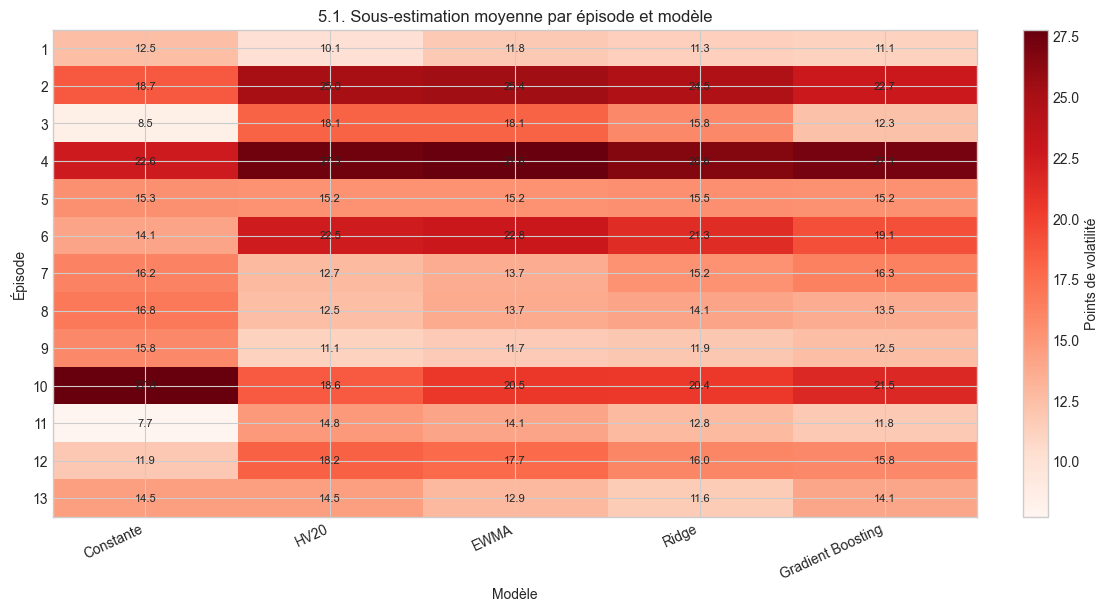

In [10]:
model_shortfall_heat = episode_model_detail.pivot(
    index='épisode', columns='modèle', values='sous_estimation_moyenne'
)[MODEL_NAMES]
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
image = ax.imshow(model_shortfall_heat.values, aspect='auto', cmap='Reds')
ax.set_xticks(range(len(MODEL_NAMES)), labels=MODEL_NAMES, rotation=25, ha='right')
ax.set_yticks(range(len(model_shortfall_heat)), labels=model_shortfall_heat.index)
ax.set(title='5.1. Sous-estimation moyenne par épisode et modèle',
       xlabel='Modèle', ylabel='Épisode')
for i in range(model_shortfall_heat.shape[0]):
    for j in range(model_shortfall_heat.shape[1]):
        ax.text(j, i, f'{model_shortfall_heat.iloc[i,j]:.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Points de volatilité')
plt.show()

## 6. Trajectoires avant, pendant et après chaque épisode

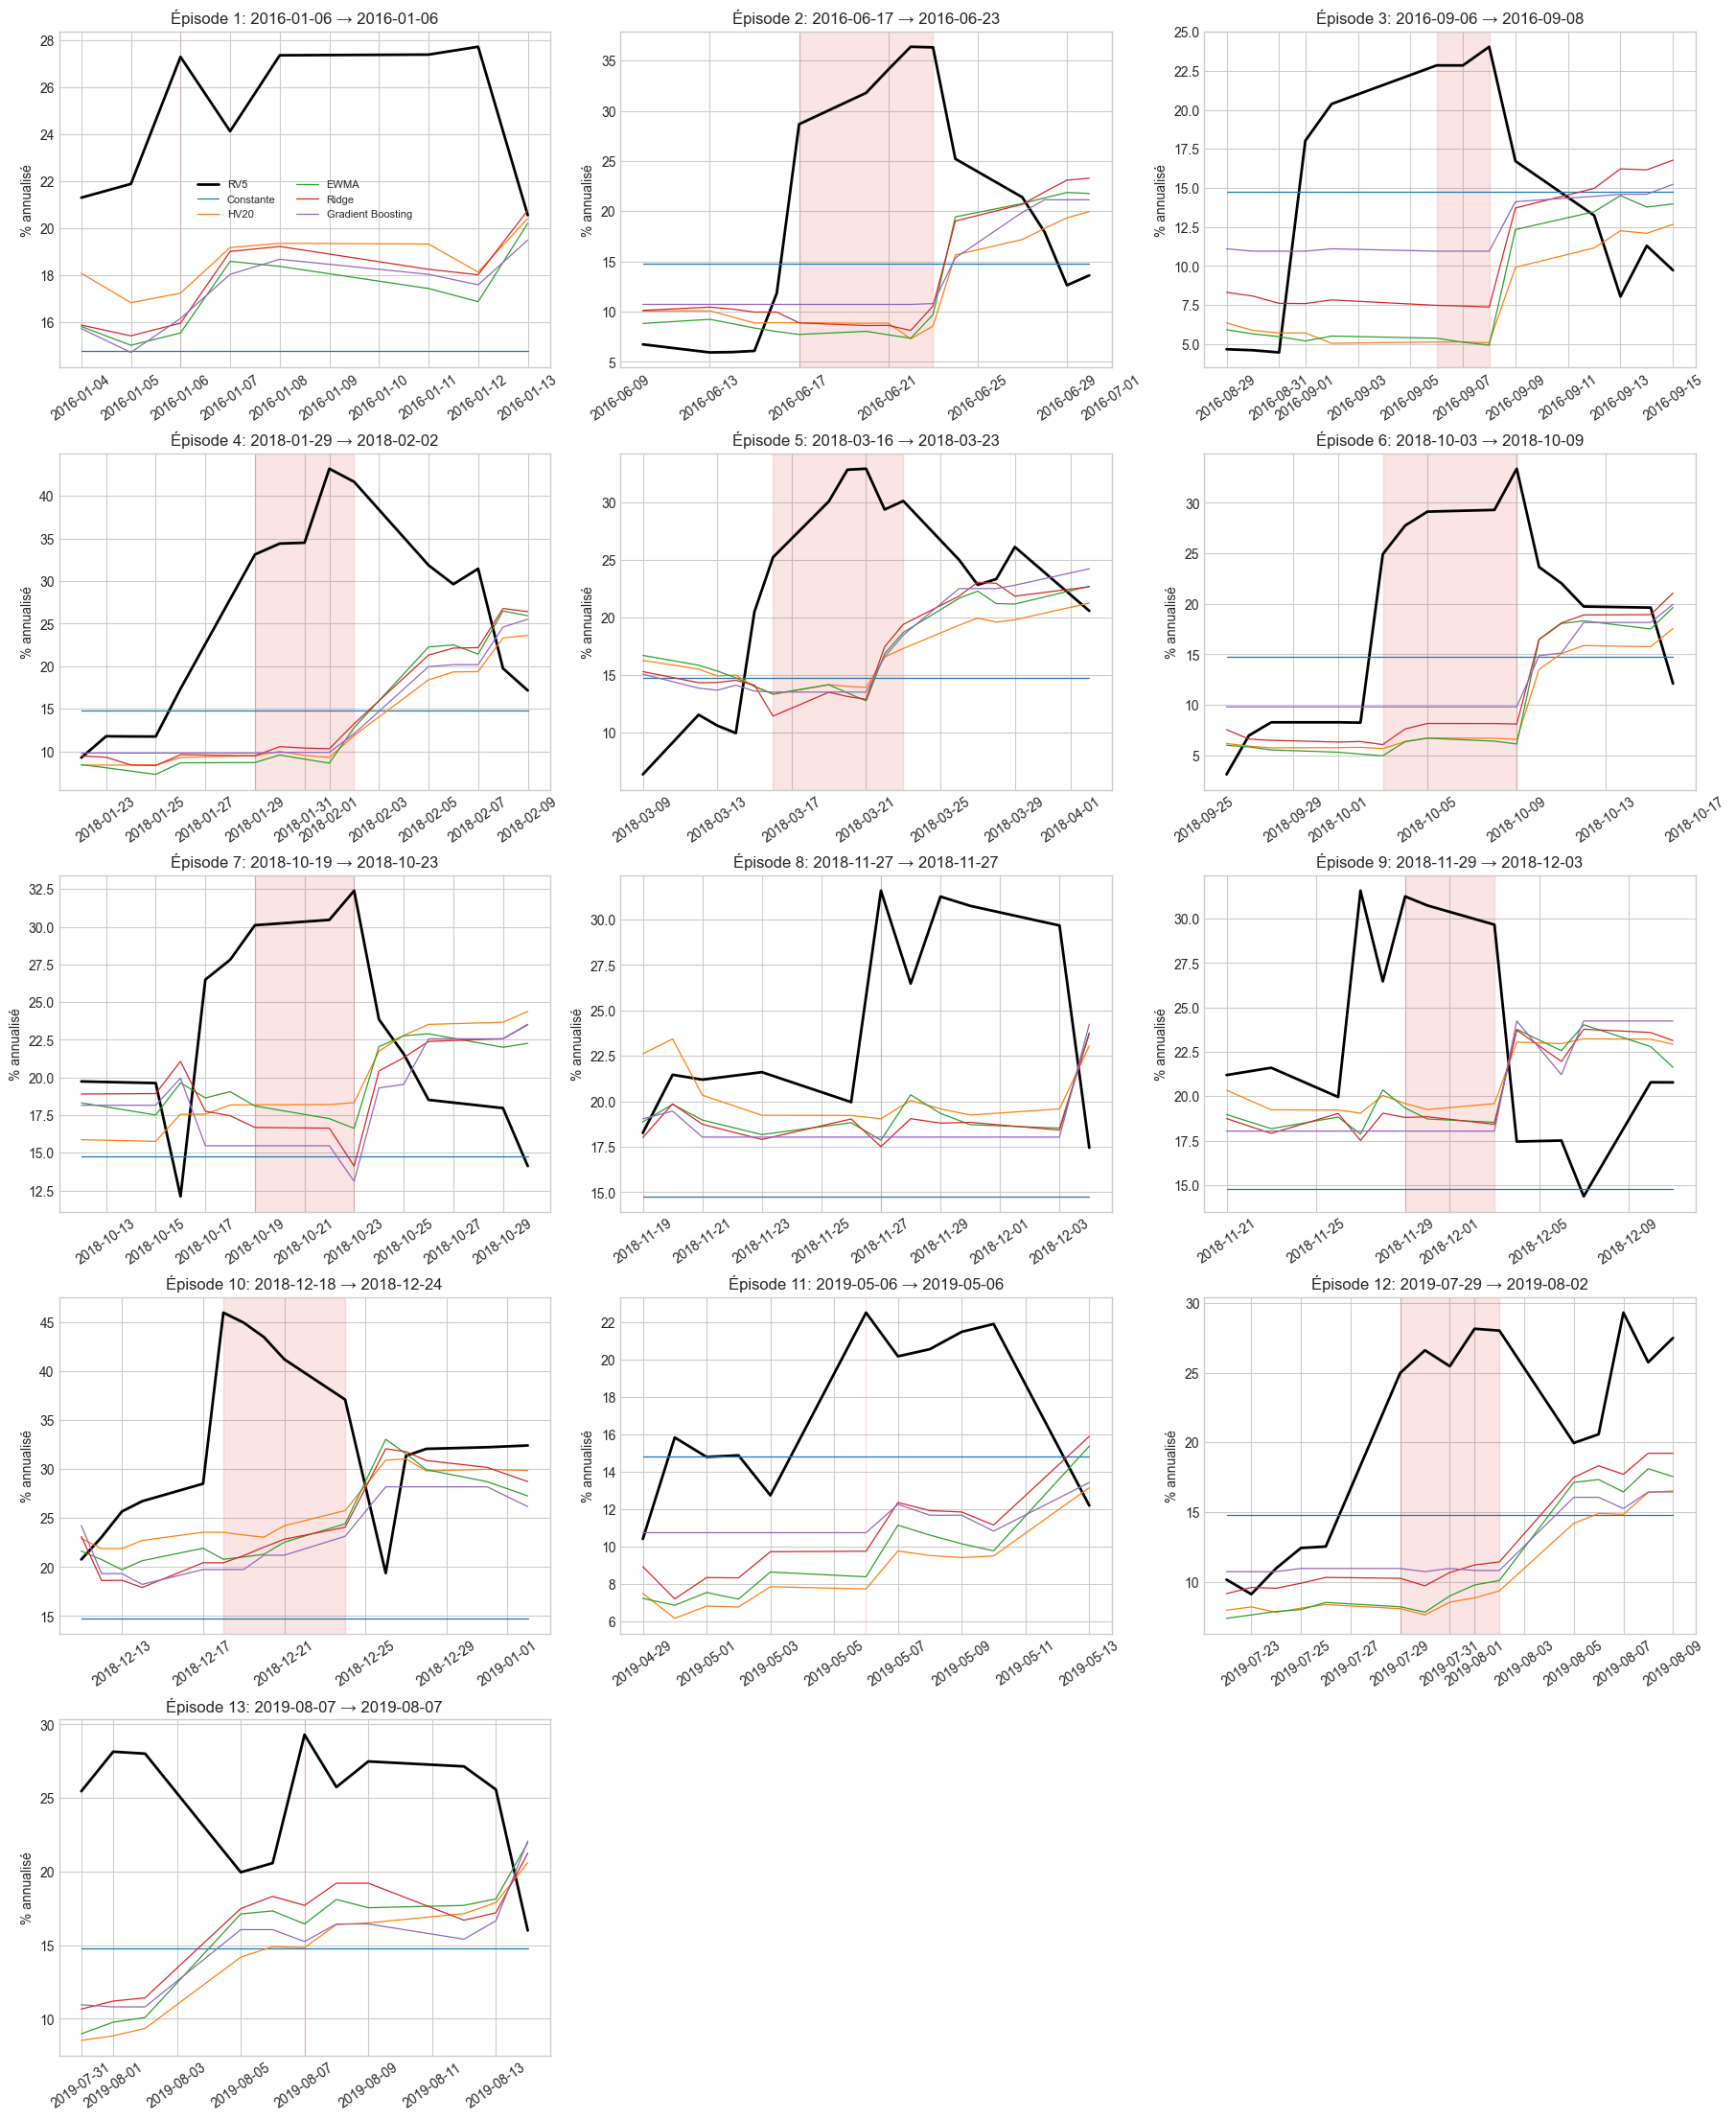

In [11]:
fig, axes = plt.subplots(5, 3, figsize=(18, 22), constrained_layout=True)
axes = axes.ravel()
for ax, (episode, row) in zip(axes, episodes.iterrows()):
    start_pos = predictions.index.get_loc(row.début_t)
    end_pos = predictions.index.get_loc(row.fin_t)
    local_index = predictions.index[max(0, start_pos-5):min(len(predictions), end_pos+6)]
    ax.plot(local_index, 100*predictions.loc[local_index, 'rv_5'], color='black', linewidth=2, label='RV5')
    for model in MODEL_NAMES:
        ax.plot(local_index, 100*predictions.loc[local_index, model], linewidth=.9, label=model)
    ax.axvspan(row.début_t, row.fin_t, color='#d62728', alpha=.12)
    ax.set_title(f'Épisode {episode}: {row.début_t.date()} → {row.fin_t.date()}')
    ax.tick_params(axis='x', rotation=35)
    ax.set_ylabel('% annualisé')
for ax in axes[len(episodes):]:
    ax.axis('off')
axes[0].legend(ncol=2, fontsize=8)
plt.show()

La zone rouge indique les origines classées après coup comme défaillances communes. Comme chaque `RV5_t` couvre cinq séances futures, des trajectoires voisines peuvent partager jusqu'à quatre rendements. La durée visuelle d'un épisode ne mesure donc pas directement la durée d'un choc économique indépendant.

## 7. Chevauchement et concentration sur les séances futures

In [12]:
future_diagnostic_rows = []
for date in predictions.index[common4]:
    position = factors.index.get_loc(date)
    next_dates = factors.index[position+1:position+1+HORIZON]
    next_returns = market_return.loc[next_dates]
    squared = next_returns.pow(2)
    dominant_date = squared.idxmax()
    future_diagnostic_rows.append({
        'date_t': date,
        'épisode': int(common_episode_id.loc[date]),
        'date_future_dominante': dominant_date,
        'décalage_dominant': int(next_dates.get_loc(dominant_date)+1),
        'rendement_dominant_pct': 100*next_returns.loc[dominant_date],
        'part_dominante_pct': 100*squared.max()/squared.sum(),
    })
future_diagnostics = pd.DataFrame(future_diagnostic_rows).set_index('date_t')
dominant_sessions = future_diagnostics.groupby('date_future_dominante').agg(
    origines_expliquées=('épisode', 'size'),
    épisodes=('épisode', 'nunique'),
    rendement_pct=('rendement_dominant_pct', 'first'),
    part_médiane_pct=('part_dominante_pct', 'median'),
).sort_values(['origines_expliquées', 'part_médiane_pct'], ascending=False)

print(f'{len(future_diagnostics)} origines communes reposent sur '
      f'{future_diagnostics.date_future_dominante.nunique()} séances futures dominantes distinctes.')
print('Séances dominantes répétées dans au moins deux cibles communes :')
print(dominant_sessions.loc[dominant_sessions.origines_expliquées >= 2].round(2).to_string())
print('Distribution du décalage de la séance dominante :')
print(future_diagnostics.décalage_dominant.value_counts().sort_index().to_string())

44 origines communes reposent sur 13 séances futures dominantes distinctes.
Séances dominantes répétées dans au moins deux cibles communes :
                       origines_expliquées  épisodes  rendement_pct  part_médiane_pct
date_future_dominante                                                                
2018-12-26                               5         1           5.08             68.81
2018-02-05                               5         1          -4.02             68.43
2019-08-05                               5         1          -3.06             66.68
2018-10-10                               5         1          -3.32             65.44
2016-06-24                               5         1          -3.69             58.94
2018-03-26                               5         1           2.68             39.86
2018-12-04                               4         2          -3.45             62.42
2018-10-24                               3         1          -3.32             59.87

In [13]:
offset_rows = []
for offset in range(HORIZON):
    spaced = predictions.iloc[offset::HORIZON]
    assert (spaced.target_start.iloc[1:].to_numpy() > spaced.target_end.iloc[:-1].to_numpy()).all()
    mask = common4.loc[spaced.index]
    offset_rows.append({
        'décalage': offset,
        'observations': len(spaced),
        'défaillances_communes': int(mask.sum()),
        'fréquence_pct': 100*mask.mean(),
        'épisodes_représentés': int(common_episode_id.loc[spaced.index][mask].nunique()),
    })
offset_common = pd.DataFrame(offset_rows).set_index('décalage')
print(offset_common.round(3).to_string())

          observations  défaillances_communes  fréquence_pct  épisodes_représentés
décalage                                                                          
0                  201                      9          4.478                     9
1                  200                      9          4.500                     9
2                  200                      9          4.500                     9
3                  200                      7          3.500                     7
4                  200                     10          5.000                     9


Les cinq décalages éliminent le partage direct de rendements à l'intérieur de chaque sous-échantillon. Ils ne rendent pas les dates historiquement indépendantes et ne constituent pas cinq tests séparés. Leur rôle est uniquement de vérifier que le constat ne dépend pas d'un seul décalage favorable.

## 8. Informations disponibles au début des épisodes

In [14]:
start_dates = pd.DatetimeIndex(episodes.début_t)
available = data.loc[predictions.index, [
    'market_return', 'abs_return_t', 'hv_5', 'hv_20', 'hv_60',
    'delta_hv5', 'ratio_hv5_hv20', 'ratio_hv20_hv60',
]].copy()
available['prévision_moyenne'] = predictions[MODEL_NAMES].mean(axis=1)
available['dispersion_prévisions'] = predictions[MODEL_NAMES].std(axis=1)
available['date_début_épisode'] = available.index.isin(start_dates)
return_q95 = float(data.loc[development.index, 'abs_return_t'].quantile(.95))

start_information = available.loc[start_dates].copy()
start_information['rendement_t_pct'] = 100*start_information.market_return
for column in ['hv_5', 'hv_20', 'hv_60', 'delta_hv5', 'prévision_moyenne', 'dispersion_prévisions']:
    start_information[f'{column}_pct'] = 100*start_information[column]
start_information['abs_return_sup_q95'] = start_information.abs_return_t > return_q95
start_information['hv5_sup_hv20'] = start_information.hv_5 > start_information.hv_20
start_information['hv20_sup_hv60'] = start_information.hv_20 > start_information.hv_60

display_columns = [
    'rendement_t_pct', 'hv_5_pct', 'hv_20_pct', 'hv_60_pct', 'delta_hv5_pct',
    'ratio_hv5_hv20', 'ratio_hv20_hv60', 'prévision_moyenne_pct',
    'dispersion_prévisions_pct', 'abs_return_sup_q95', 'hv5_sup_hv20', 'hv20_sup_hv60',
]
print(f'Seuil descriptif du 95e centile de |r_t| sur 1990–2015 : {100*return_q95:.3f} %.')
print(start_information[display_columns].round(3).to_string())

Seuil descriptif du 95e centile de |r_t| sur 1990–2015 : 2.280 %.
            rendement_t_pct  hv_5_pct  hv_20_pct  hv_60_pct  delta_hv5_pct  ratio_hv5_hv20  ratio_hv20_hv60  prévision_moyenne_pct  dispersion_prévisions_pct  abs_return_sup_q95  hv5_sup_hv20  hv20_sup_hv60
début_t                                                                                                                                                                                                       
2016-01-06            -1.34    17.001     17.233     14.912          1.060           0.987            1.156                 15.931                      0.899               False         False           True
2016-06-17            -0.30     6.740      8.892     10.044         -3.081           0.758            0.885                 10.200                      2.772               False         False          False
2016-09-06             0.27     4.666      5.134     12.798         -1.013           0.909            0.40

In [15]:
comparison_rows = []
for label, frame in [
    ('Débuts des 13 épisodes', available.loc[start_dates]),
    ('Autres dates 2016–2019', available.loc[~available.index.isin(predictions.index[common4])]),
]:
    comparison_rows.append({
        'groupe': label,
        'n': len(frame),
        'médiane_abs_r_pct': 100*frame.abs_return_t.median(),
        'q75_abs_r_pct': 100*frame.abs_return_t.quantile(.75),
        'médiane_HV5_pct': 100*frame.hv_5.median(),
        'médiane_HV20_pct': 100*frame.hv_20.median(),
        'médiane_HV60_pct': 100*frame.hv_60.median(),
        'HV5_sup_HV20_pct': 100*(frame.hv_5 > frame.hv_20).mean(),
        'HV20_sup_HV60_pct': 100*(frame.hv_20 > frame.hv_60).mean(),
        'abs_r_sup_q95_pct': 100*(frame.abs_return_t > return_q95).mean(),
        'dispersion_prévision_médiane_pct': 100*frame.dispersion_prévisions.median(),
    })
available_comparison = pd.DataFrame(comparison_rows).set_index('groupe')
print(available_comparison.round(3).to_string())

                          n  médiane_abs_r_pct  q75_abs_r_pct  médiane_HV5_pct  médiane_HV20_pct  médiane_HV60_pct  HV5_sup_HV20_pct  HV20_sup_HV60_pct  abs_r_sup_q95_pct  dispersion_prévision_médiane_pct
groupe                                                                                                                                                                                                      
Débuts des 13 épisodes   13               0.26           0.31           10.385            13.328            12.798            38.462             53.846              0.000                             2.455
Autres dates 2016–2019  957               0.37           0.78            8.973             9.694            11.613            37.931             42.424              2.403                             2.759


Cette comparaison est descriptive et sélectionnée après observation des erreurs. Elle peut montrer qu'une information simple était ou non déjà élevée à `t`; elle ne mesure ni capacité de détection hors échantillon ni causalité.

## 9. Dynamique moyenne alignée sur le début des épisodes

In [16]:
relative_rows = []
for episode, start_date in episodes.début_t.items():
    start_position = predictions.index.get_loc(start_date)
    for relative in range(-10, 16):
        position = start_position + relative
        if not 0 <= position < len(predictions):
            continue
        date = predictions.index[position]
        row = {
            'épisode': episode, 'relative': relative, 'date': date,
            'rv5_pct': 100*predictions.loc[date, 'rv_5'],
            'prévision_moyenne_pct': 100*predictions.loc[date, MODEL_NAMES].mean(),
            'prévision_min_pct': 100*predictions.loc[date, MODEL_NAMES].min(),
            'prévision_max_pct': 100*predictions.loc[date, MODEL_NAMES].max(),
            'hv5_pct': 100*data.loc[date, 'hv_5'],
            'hv20_pct': 100*data.loc[date, 'hv_20'],
            'hv60_pct': 100*data.loc[date, 'hv_60'],
        }
        relative_rows.append(row)
relative_paths = pd.DataFrame(relative_rows)
aligned = relative_paths.groupby('relative').agg(
    rv5_médiane=('rv5_pct', 'median'),
    rv5_q25=('rv5_pct', lambda x: x.quantile(.25)),
    rv5_q75=('rv5_pct', lambda x: x.quantile(.75)),
    prévision_médiane=('prévision_moyenne_pct', 'median'),
    prévision_q25=('prévision_moyenne_pct', lambda x: x.quantile(.25)),
    prévision_q75=('prévision_moyenne_pct', lambda x: x.quantile(.75)),
    hv5_médiane=('hv5_pct', 'median'),
    hv20_médiane=('hv20_pct', 'median'),
    hv60_médiane=('hv60_pct', 'median'),
    n=('épisode', 'nunique'),
)
print(aligned.round(3).to_string())

          rv5_médiane  rv5_q25  rv5_q75  prévision_médiane  prévision_q25  prévision_q75  hv5_médiane  hv20_médiane  hv60_médiane   n
relative                                                                                                                             
-10            10.655    7.963   17.742             10.164          9.430         18.018        8.142         8.375        12.442  12
-9             11.269    7.552   17.934             10.280          9.644         18.689        8.600         8.574        12.481  12
-8             11.347    7.223   18.330             10.356          9.847         17.435        9.335         8.332        12.514  12
-7             11.864    7.178   18.549             10.464          9.927         16.982       10.555         9.078        12.450  12
-6             11.884    9.865   21.605             10.204          9.964         16.727        9.515         8.642        12.366  12
-5             10.263    6.648   19.997             10.840    

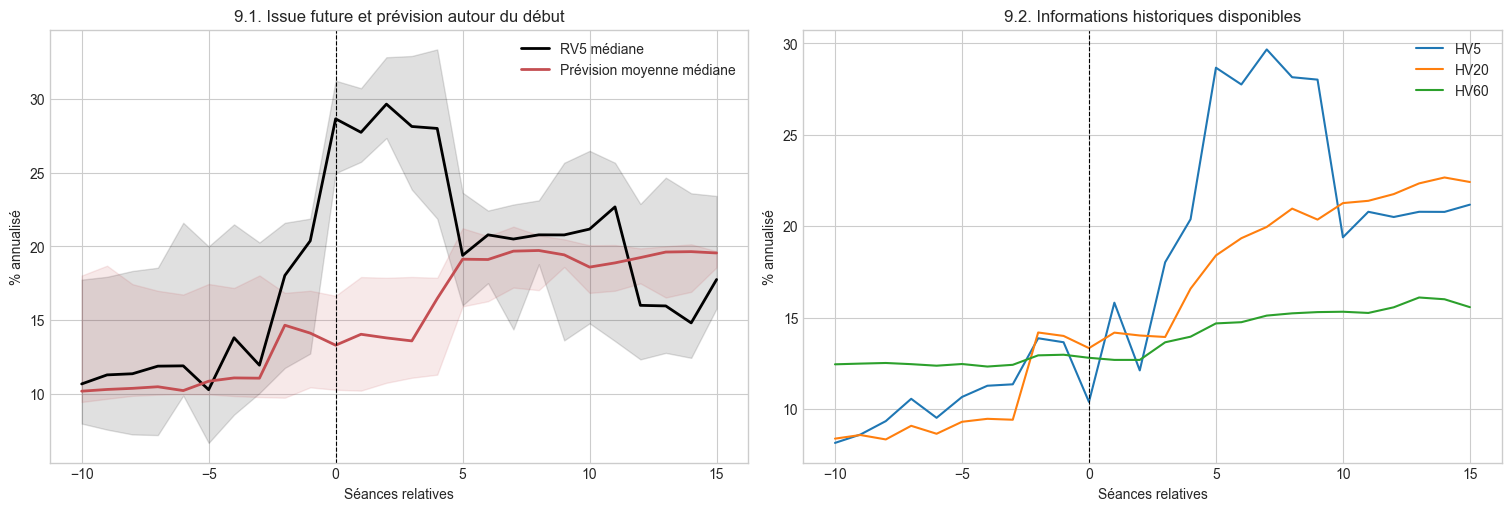

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
x = aligned.index.to_numpy()
axes[0].plot(x, aligned.rv5_médiane, color='black', linewidth=2, label='RV5 médiane')
axes[0].fill_between(x, aligned.rv5_q25, aligned.rv5_q75, color='black', alpha=.12)
axes[0].plot(x, aligned.prévision_médiane, color='#c44e52', linewidth=2, label='Prévision moyenne médiane')
axes[0].fill_between(x, aligned.prévision_q25, aligned.prévision_q75, color='#c44e52', alpha=.12)
axes[0].axvline(0, color='black', linestyle='--', linewidth=.8)
axes[0].set(title='9.1. Issue future et prévision autour du début', xlabel='Séances relatives', ylabel='% annualisé')
axes[0].legend()

axes[1].plot(x, aligned.hv5_médiane, label='HV5')
axes[1].plot(x, aligned.hv20_médiane, label='HV20')
axes[1].plot(x, aligned.hv60_médiane, label='HV60')
axes[1].axvline(0, color='black', linestyle='--', linewidth=.8)
axes[1].set(title='9.2. Informations historiques disponibles', xlabel='Séances relatives', ylabel='% annualisé')
axes[1].legend()
plt.show()

## 10. Réaction tardive ou information absente de la série historique ?

In [18]:
start_outcome_rows = []
return_q99 = float(data.loc[development.index, 'abs_return_t'].quantile(.99))
for episode, start_date in episodes.début_t.items():
    future = future_diagnostics.loc[start_date]
    end_date = episodes.loc[episode, 'fin_t']
    start_forecast = 100*predictions.loc[start_date, MODEL_NAMES].mean()
    end_forecast = 100*predictions.loc[end_date, MODEL_NAMES].mean()
    start_outcome_rows.append({
        'épisode': episode,
        'début_t': start_date,
        'durée': episodes.loc[episode, 'durée_origines'],
        'HV5_sup_HV20_au_début': bool(data.loc[start_date, 'hv_5'] > data.loc[start_date, 'hv_20']),
        '|r_t|_sup_q95_au_début': bool(data.loc[start_date, 'abs_return_t'] > return_q95),
        'prévision_moyenne_début_pct': start_forecast,
        'prévision_moyenne_fin_pct': end_forecast,
        'variation_prévision_pct': end_forecast-start_forecast,
        'décalage_choc_futur': int(future.décalage_dominant),
        'rendement_futur_dominant_pct': future.rendement_dominant_pct,
        'futur_dominant_sup_q99': bool(abs(future.rendement_dominant_pct/100) > return_q99),
        'part_future_dominante_pct': future.part_dominante_pct,
    })
start_outcomes = pd.DataFrame(start_outcome_rows).set_index('épisode')
print(f'Seuil descriptif q99 de |r| sur 1990–2015 : {100*return_q99:.3f} %.')
print(start_outcomes.round(3).to_string())
print('Comptages aux débuts :')
print(pd.Series({
    'HV5 > HV20': int(start_outcomes['HV5_sup_HV20_au_début'].sum()),
    '|r_t| > q95': int(start_outcomes['|r_t|_sup_q95_au_début'].sum()),
    'rendement futur dominant > q99': int(start_outcomes.futur_dominant_sup_q99.sum()),
    'prévision moyenne augmente pendant épisode': int(start_outcomes.variation_prévision_pct.gt(0).sum()),
}).to_string())

Seuil descriptif q99 de |r| sur 1990–2015 : 3.940 %.
           début_t  durée  HV5_sup_HV20_au_début  |r_t|_sup_q95_au_début  prévision_moyenne_début_pct  prévision_moyenne_fin_pct  variation_prévision_pct  décalage_choc_futur  rendement_futur_dominant_pct  futur_dominant_sup_q99  part_future_dominante_pct
épisode                                                                                                                                                                                                                                                        
1       2016-01-06      1                  False                   False                       15.931                     15.931                    0.000                    5                         -2.66                   False                     47.862
2       2016-06-17      5                  False                   False                       10.200                     10.879                    0.679                    5     

La présence d'un rendement futur dominant extrême montre qu'une partie de l'issue n'était pas contenue dans les rendements déjà observés. L'augmentation ultérieure des prévisions montre seulement une réaction après incorporation de nouvelles observations. Elle ne permet pas d'affirmer que toute l'erreur était imprévisible, ni qu'une autre information disponible à `t` n'aurait pas pu aider.

## 11. Erreurs communes et erreurs propres aux modèles

In [19]:
specific_rows = []
for model in MODEL_NAMES:
    model_fail = large_under[model]
    specific_rows.append({
        'modèle': model,
        'dates_fortes_total': int(model_fail.sum()),
        'dans_défaillance_commune': int((model_fail & common4).sum()),
        'hors_défaillance_commune': int((model_fail & ~common4).sum()),
        'part_dans_commun_pct': 100*(model_fail & common4).sum()/model_fail.sum(),
        'dates_communes_où_modèle_ne_franchit_pas': int((common4 & ~model_fail).sum()),
    })
specific_failures = pd.DataFrame(specific_rows).set_index('modèle')

exceptions = []
for date in predictions.index[common4 & ~common5]:
    exceptions.append({
        'date_t': date,
        'épisode': int(common_episode_id.loc[date]),
        'modèle_exception': ', '.join(large_under.columns[~large_under.loc[date]].tolist()),
        'RV5_pct': 100*predictions.loc[date, 'rv_5'],
    })
exception_table = pd.DataFrame(exceptions).set_index('date_t')
print(specific_failures.round(2).to_string())
print('Dates 4/5 et modèle ne franchissant pas le seuil :')
print(exception_table.round(3).to_string())

                   dates_fortes_total  dans_défaillance_commune  hors_défaillance_commune  part_dans_commun_pct  dates_communes_où_modèle_ne_franchit_pas
modèle                                                                                                                                                   
Constante                          57                        36                        21                 63.16                                         8
HV20                               53                        42                        11                 79.25                                         2
EWMA                               52                        44                         8                 84.62                                         0
Ridge                              44                        43                         1                 97.73                                         1
Gradient Boosting                  51                        44             

## 12. Benchmark initial contre configurations étendues

In [20]:
ridge_extended, boosting_extended = fitted_ml_predictions(
    1000,
    {'learning_rate': .10, 'n_estimators': 50, 'max_depth': 1, 'min_samples_leaf': 10},
)
extended = predictions[['rv_5', 'target_start', 'target_end']].copy()
extended['Constante'] = predictions.Constante
extended['HV20'] = predictions.HV20
extended['EWMA'] = predictions.EWMA
extended['Ridge étendue'] = ridge_extended
extended['Boosting étendu'] = boosting_extended
extended_errors = pd.DataFrame({
    model: 100*(extended[model] - extended.rv_5) for model in EXTENDED_MODEL_NAMES
})
extended_large_under = extended_errors.le(-COMMON_THRESHOLD)
extended_count = extended_large_under.sum(axis=1)
extended_common4 = extended_count.ge(4)
extended_episode_id = episode_ids(extended_common4)

intersection = int((common4 & extended_common4).sum())
union = int((common4 | extended_common4).sum())
comparison = pd.Series({
    'dates_initiales': int(common4.sum()),
    'épisodes_initiaux': int(common_episode_id.nunique()),
    'dates_étendues': int(extended_common4.sum()),
    'épisodes_étendus': int(extended_episode_id.nunique()),
    'dates_communes_aux_deux': intersection,
    'dates_union': union,
    'Jaccard_pct': 100*intersection/union,
    'ajoutées_par_étendu': int((extended_common4 & ~common4).sum()),
    'retirées_par_étendu': int((common4 & ~extended_common4).sum()),
})
changed_dates = pd.DataFrame({
    'initial_4sur5': common4,
    'étendu_4sur5': extended_common4,
    'nombre_initial': failure_count,
    'nombre_étendu': extended_count,
}).loc[common4.ne(extended_common4)]

assert int(extended_common4.sum()) == 45 and extended_episode_id.nunique() == 13
print(comparison.round(3).to_string())
print('Dates dont le classement change :')
print(changed_dates.to_string())

dates_initiales            44.000
épisodes_initiaux          13.000
dates_étendues             45.000
épisodes_étendus           13.000
dates_communes_aux_deux    44.000
dates_union                45.000
Jaccard_pct                97.778
ajoutées_par_étendu         1.000
retirées_par_étendu         0.000
Dates dont le classement change :
            initial_4sur5  étendu_4sur5  nombre_initial  nombre_étendu
date                                                                  
2018-02-05          False          True               3              4


## 13. Synthèse scientifique

La synthèse finale distingue les faits établis par ces calculs, les interprétations compatibles avec eux et ce que le protocole ne permet toujours pas de trancher.

In [21]:
print('RÉSUMÉ CALCULÉ')
print(f'Seuil commun : {COMMON_THRESHOLD:.3f} points.')
print(f'Benchmark initial : {common4.sum()} dates, {common_episode_id.nunique()} épisodes; '
      f'{common5.sum()} dates en 5/5.')
print(f'Origines communes → séances futures dominantes distinctes : '
      f'{len(future_diagnostics)} → {future_diagnostics.date_future_dominante.nunique()}.')
print(f'Part dominante médiane : {future_diagnostics.part_dominante_pct.median():.1f} %.')
print(f'Aux 13 débuts : HV5>HV20 dans {start_outcomes["HV5_sup_HV20_au_début"].sum()} cas; '
      f'|r_t|>q95 dans {start_outcomes["|r_t|_sup_q95_au_début"].sum()} cas; '
      f'choc futur dominant>q99 dans {start_outcomes.futur_dominant_sup_q99.sum()} cas.')
print(f'La prévision moyenne augmente entre début et fin dans '
      f'{start_outcomes.variation_prévision_pct.gt(0).sum()}/13 épisodes.')
print(f'Classification initiale/étendue : Jaccard={comparison.Jaccard_pct:.1f} %, '
      f'ajouts={int(comparison["ajoutées_par_étendu"])}, retraits={int(comparison["retirées_par_étendu"])}.')

RÉSUMÉ CALCULÉ
Seuil commun : 10.931 points.
Benchmark initial : 44 dates, 13 épisodes; 33 dates en 5/5.
Origines communes → séances futures dominantes distinctes : 44 → 13.
Part dominante médiane : 60.7 %.
Aux 13 débuts : HV5>HV20 dans 5 cas; |r_t|>q95 dans 0 cas; choc futur dominant>q99 dans 2 cas.
La prévision moyenne augmente entre début et fin dans 6/13 épisodes.
Classification initiale/étendue : Jaccard=97.8 %, ajouts=1, retraits=0.


### 13.1. Faits, interprétations et limites

**Faits empiriquement établis.** Les cinq modèles sont reconstruits sur les mêmes 1 001 dates et leurs métriques concordent avec le notebook 05. Avec le seuil commun de 10,931 points, le benchmark initial contient 44 origines en défaillance commune, regroupées en 13 épisodes; les cinq modèles franchissent le seuil sur 33 de ces dates. Les configurations étendues retrouvent 44 de ces 44 dates et en ajoutent une seule, soit un indice de Jaccard de 97,8 %. Le constat dépend donc très peu de l'approfondissement des hyperparamètres.

**Effet du chevauchement.** Les 44 origines se ramènent à 13 séances futures dominantes distinctes. Une seule séance dominante explique une part médiane de 60,7 % de la somme des cinq rendements au carré et peut apparaître dans jusqu'à cinq cibles communes. Le chevauchement amplifie donc fortement les effectifs. Il n'explique cependant pas tout : chacun des cinq décalages non chevauchants contient encore 7 à 10 défaillances communes et représente 7 à 9 épisodes.

**Information disponible au début.** Aucun des 13 débuts ne présente un rendement courant dépassant le 95e centile historique de `|r_t|`. `HV5` dépasse `HV20` dans 5 cas sur 13, une proportion presque identique à celle des autres dates, et la dispersion médiane entre prévisions est légèrement plus faible aux débuts. Les modèles ne semblent donc pas échouer parce qu'ils expriment des diagnostics radicalement divergents. Les niveaux médians de `HV20` et `HV60` sont toutefois plus élevés aux débuts que sur les autres dates : certains épisodes commencent dans un environnement déjà plus volatil, sans signal simple et uniforme d'accélération immédiate.

**Réaction tardive et information non encore observée.** La séance future dominante arrive à chacun des cinq décalages possibles; à l'origine correspondante elle est, par définition, inconnue. Elle dépasse le 99e centile historique dans seulement 2 épisodes sur 13 : les défaillances ne se réduisent donc pas à deux chocs exceptionnellement extrêmes. La prévision moyenne augmente entre le début et la fin dans 6 épisodes sur 13, tandis qu'elle stagne ou diminue dans les autres, notamment les épisodes d'une seule origine. Une réaction retardée est compatible avec une partie des trajectoires, mais ne constitue pas un mécanisme universel.

**Erreurs partagées et spécifiques.** L'EWMA et le Boosting franchissent le seuil lors des 44 dates communes; la Ridge dans 43 et `HV20` dans 42. La constante est l'exception la plus fréquente sur les dates 4/5, car son niveau fixe est parfois suffisamment élevé pour éviter le seuil. Inversement, tous les modèles connaissent aussi quelques grandes sous-estimations hors des épisodes communs. Une architecture différente ne suffit donc ni à produire exactement les mêmes erreurs ni à éviter le noyau commun.

**Interprétations plausibles.** Les modèles utilisent des transformations différentes mais la même information historique et exploitent tous, directement ou indirectement, la persistance de l'amplitude. Leur accord avant plusieurs épisodes, puis leur sous-estimation simultanée, est compatible avec une limite informationnelle commune. L'entrée progressive d'un rendement nouvellement observé dans `HV5`, l'EWMA et les modèles fondés sur les horizons historiques est compatible avec une adaptation après le mouvement. Ces observations ne déterminent pas si une autre information disponible à `t` aurait permis de mieux prévoir.

**Limites méthodologiques.** L'analyse rétrospective ne démontre ni que les épisodes étaient détectables, ni qu'ils étaient imprévisibles avec toute information disponible sur les marchés, ni qu'un mécanisme économique particulier les cause. Les seuils descriptifs du 95e et du 99e centile ne sont pas des règles de décision. Les épisodes restent historiquement liés, les trajectoires alignées ne sont pas indépendantes et 2016–2019 a déjà été examinée. Une sous-estimation de volatilité n'est pas automatiquement une perte financière.

**Questions encore ouvertes.** Les résultats justifient seulement de demander : (1) quelle part d'un épisode aurait pu être signalée avant sa première défaillance; (2) quelles informations réellement disponibles à `t`, mais absentes de la seule série de rendements, pourraient distinguer les débuts d'épisodes; (3) quelle décision financière donnerait un coût explicite aux sous-estimations et surestimations. Chacune exige un protocole distinct et une nouvelle validation.

**Arrêt.** Aucun modèle, donnée, réglage, test ou nouvelle phase n'est engagé par ce notebook.